In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/asifxzaman/chattogram-weather-dataset20192023/chattogram_weather_5years.csv


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns


In [3]:
df=pd.read_csv("/kaggle/input/datasets/asifxzaman/chattogram-weather-dataset20192023/chattogram_weather_5years.csv")
df.info()
df.head()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1826 entries, 0 to 1825
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Date         1826 non-null   object 
 1   Temp_C       1826 non-null   float64
 2   Humidity_%   1826 non-null   int64  
 3   Rainfall_mm  1826 non-null   float64
 4   Wind_kmh     1826 non-null   int64  
 5   Condition    1826 non-null   object 
dtypes: float64(2), int64(2), object(2)
memory usage: 85.7+ KB


,Temp_C,Humidity_%,Rainfall_mm,Wind_kmh
count,1826.000000,1826.000000,1826.000000,1826.000000
mean,25.778970,75.333516,8.735433,14.916758
std,3.209077,9.352515,11.125410,4.289353
min,19.000000,60.000000,0.000000,8.000000
25%,22.800000,68.000000,0.000000,11.000000
50%,26.700000,75.000000,4.500000,15.000000
75%,28.300000,83.000000,12.375000,19.000000
max,31.000000,92.000000,69.000000,22.000000


In [4]:
#missing value check
print(df.isnull().sum())
#duplicate value check
print(df.duplicated().sum())

Date           0
Temp_C         0
Humidity_%     0
Rainfall_mm    0
Wind_kmh       0
Condition      0
dtype: int64
0


In [5]:
#date convert
df["Date"]=pd.to_datetime(df["Date"])
df["month"]=df["Date"].dt.month
df["year"]=df["Date"].dt.year
df["day"]=df["Date"].dt.day
print(df["day"])
print(df["month"])
print(df["year"])

0        1
1        2
2        3
3        4
4        5
        ..
1821    27
1822    28
1823    29
1824    30
1825    31
Name: day, Length: 1826, dtype: int32
0        1
1        1
2        1
3        1
4        1
        ..
1821    12
1822    12
1823    12
1824    12
1825    12
Name: month, Length: 1826, dtype: int32
0       2019
1       2019
2       2019
3       2019
4       2019
        ... 
1821    2023
1822    2023
1823    2023
1824    2023
1825    2023
Name: year, Length: 1826, dtype: int32


In [6]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
df["Condition"]=le.fit_transform(df["Condition"])

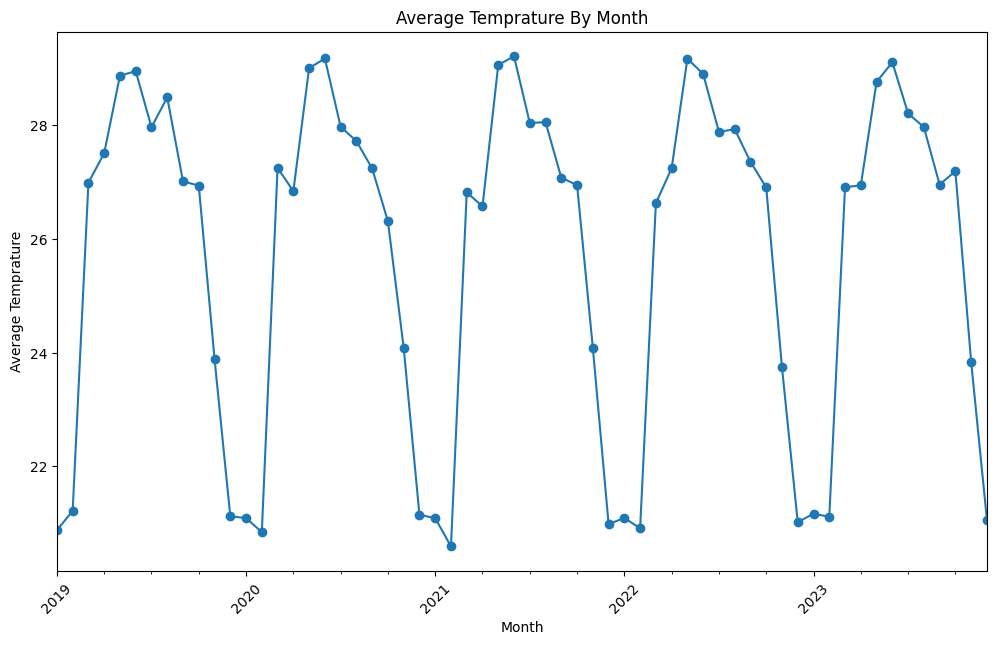

'the temprature exhibits a recurring seasonal pattern across yeras,with peaks around 29-30°C\nand lows around 20-21°C.No significant long-term increasing or decreasing trend is observed'

In [7]:
                           #exploratory data analysis
#tempreture trend(monthly)
monthly_avg=df.groupby(df["Date"].dt.to_period("M"))["Temp_C"].mean()
plt.figure(figsize=(12,7))
monthly_avg.plot(marker="o")
plt.title("Average Temprature By Month")
plt.xlabel("Month")
plt.ylabel("Average Temprature")
plt.xticks(rotation=45)
plt.show()
'''the temprature exhibits a recurring seasonal pattern across yeras,with peaks around 29-30°C
and lows around 20-21°C.No significant long-term increasing or decreasing trend is observed'''

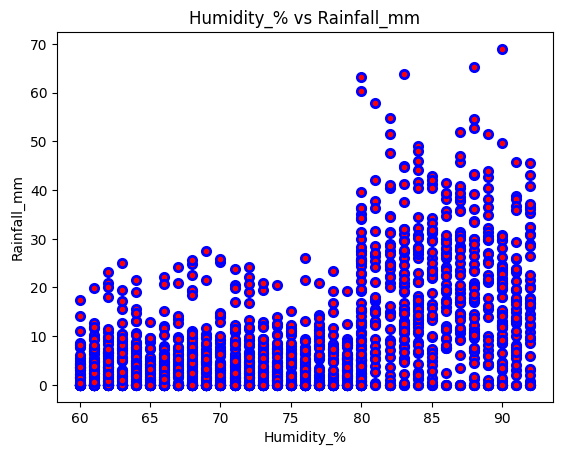

In [8]:
# humidity_% vs rainfall
plt.scatter(df["Humidity_%"],df["Rainfall_mm"],color="r",edgecolor="b",linewidth=2)
plt.xlabel("Humidity_%")
plt.ylabel("Rainfall_mm")
plt.title("Humidity_% vs Rainfall_mm")
plt.show()
#Higher humidity generally shows greater rainfall tendency

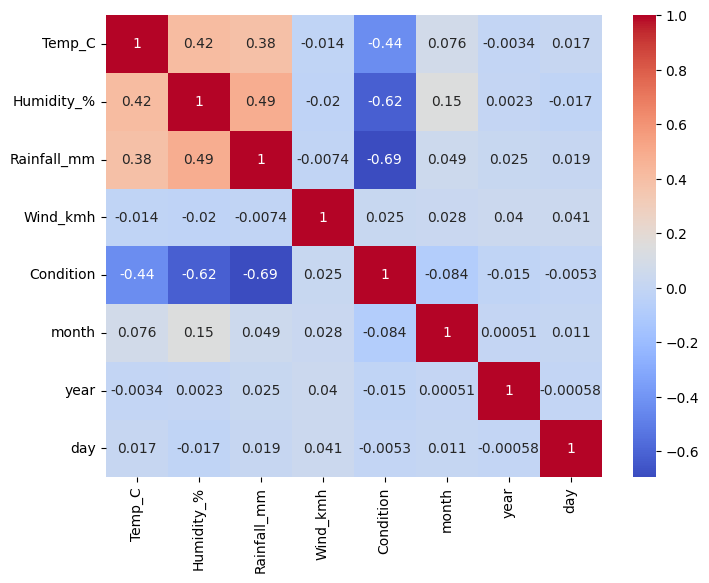

In [9]:
#Correlation heatmap
corr=df.corr(numeric_only=True)
plt.figure(figsize=(8,6))
sns.heatmap(corr,annot=True,cmap="coolwarm")
plt.show()
#rainfall appears positively correlated with humidity and negatively related to temperature
#Wind speed has very weak correlation with other variables.
#Tempreture and condition have a moderate negative correlation

R² Score: 0.8231302894032265
MAE: 2.956607508074729


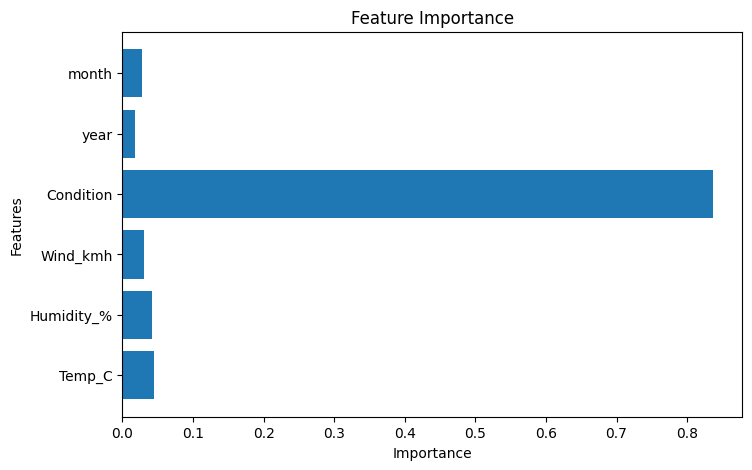

'Weather condition is the dominant predictor with the highest importance score, while \ntemperature, humidity, wind speed, month, and year contribute comparatively less to the\nprediction'

In [10]:

#covert into string to float
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

for col in df.select_dtypes(include='object').columns:
    df[col] = le.fit_transform(df[col])
    
# Step 1: Import libraries

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score,mean_absolute_error
import matplotlib.pyplot as plt

# Step 2: Missing value remove

df = df.dropna()

# Step 3: Date feature engineering

df['Date'] = pd.to_datetime(df['Date'])

df['year'] = df['Date'].dt.year
df['month'] = df['Date'].dt.month

# Step 4: Features and Target

X = df[['Temp_C',
        'Humidity_%',
        'Wind_kmh',
        'Condition',
        'year',
        'month']]

y = df['Rainfall_mm']

# Step 5: Train Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Step 6: Random Forest Model

model = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    min_samples_split=5,
    random_state=42
)

# Step 7: Train Model

model.fit(X_train,y_train)

# Step 8: Prediction

y_pred = model.predict(X_test)

# Step 9: Model Evaluation

r2 = r2_score(y_test,y_pred)
mae = mean_absolute_error(y_test,y_pred)

print("R² Score:",r2)
print("MAE:",mae)

# Step 10: Feature Importance

importance = model.feature_importances_

plt.figure(figsize=(8,5))

plt.barh(X.columns,importance)

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Feature Importance")

plt.show()
'''Weather condition is the dominant predictor with the highest importance score, while 
temperature, humidity, wind speed, month, and year contribute comparatively less to the
prediction'''


In [11]:
                   #business insight
#Weather condition is the strongest factor affecting rainfall prediction Different weather conditions significantly influence rainfall occurrence.

#Higher humidity levels increase the probability of rainfall.Days with high humidity tend to experience more rainfall.

#Temperature follows a seasonal pattern across different months.Temperature variations can help identify seasonal weather behavior.

#Wind speed has minimal impact on weather prediction.Wind speed contributes less compared to other weather factors.

#Accurate weather prediction can support agriculture and travel planning.Early weather forecasting helps farmers and travelers make better decisions.

#Weather analysis can assist disaster preparedness and resource management.Predicting weather conditions can improve planning for heavy rain and extreme conditions.
